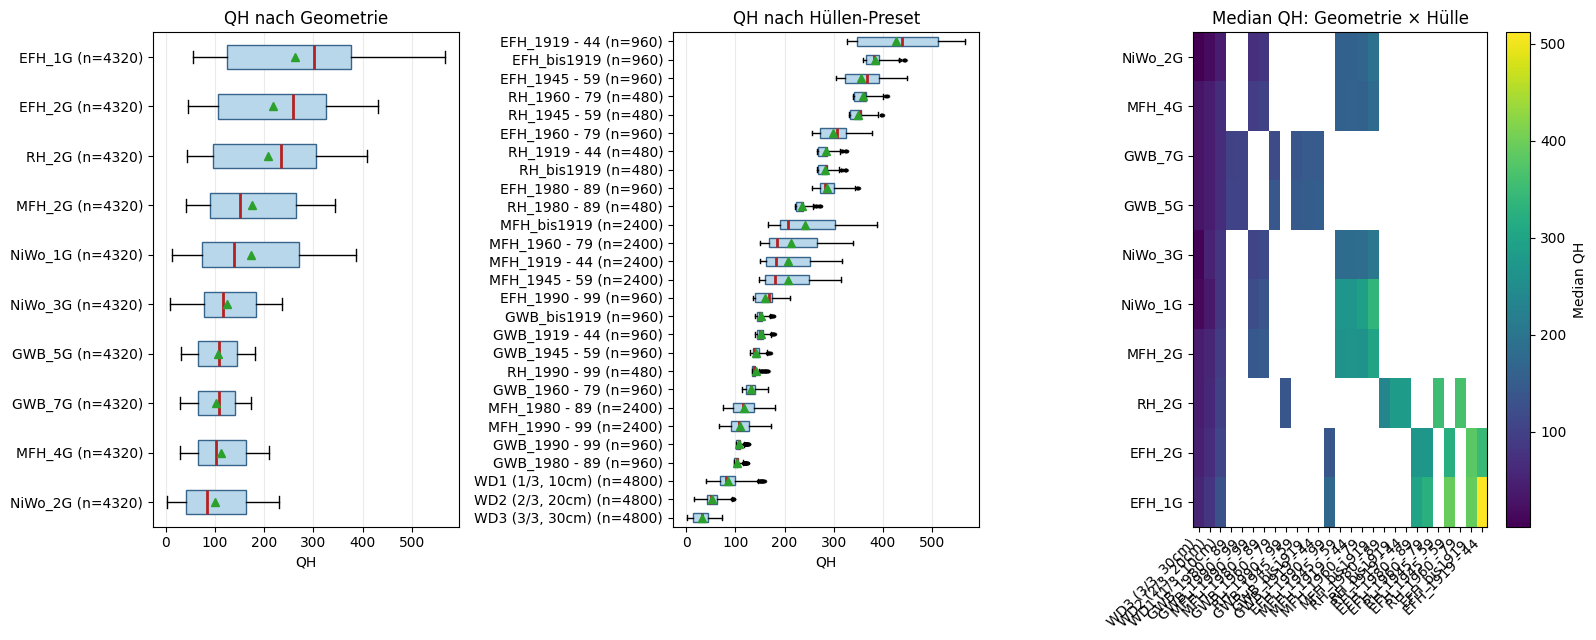

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

datei = Path(r"C:\Users\ma0026.NB-MA0026\Documents\peexcel\data\building_typologies\building_sector_v3\scenarios_harmonisiert.parquet")
geo, hull, wert = "preset_recorded_geometry", "preset_recorded_hulls", "QH"

df = pd.read_parquet(datei, columns=[geo, hull, wert])
df[wert] = pd.to_numeric(df[wert], errors="raise")
df[[geo, hull]] = df[[geo, hull]].astype("string").fillna("(fehlend)")
df = df.dropna(subset=[wert])

def boxplot(ax, spalte, titel):
    reihenfolge = df.groupby(spalte)[wert].median().sort_values().index
    gruppen = [df.loc[df[spalte] == k, wert] for k in reihenfolge]
    ax.boxplot(gruppen, vert=False, showmeans=True, patch_artist=True,
               boxprops=dict(facecolor="#b9d7ea", edgecolor="#36648b"),
               medianprops=dict(color="#b22222", linewidth=2),
               flierprops=dict(marker=".", markersize=3, alpha=0.4))
    ax.set_yticks(range(1, len(reihenfolge) + 1))
    ax.set_yticklabels([f"{k} (n={len(g)})" for k, g in zip(reihenfolge, gruppen)])
    ax.set_title(titel)
    ax.set_xlabel(wert)
    ax.grid(axis="x", alpha=0.25)

pivot = df.pivot_table(index=geo, columns=hull, values=wert, aggfunc="median")
pivot = pivot.loc[pivot.median(axis=1).sort_values().index,
                  pivot.median(axis=0).sort_values().index]

fig = plt.figure(figsize=(16, max(5, 0.45 * len(pivot) + 2)))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.2])
boxplot(fig.add_subplot(gs[0]), geo, "QH nach Geometrie")
boxplot(fig.add_subplot(gs[1]), hull, "QH nach Hüllen-Preset")

ax = fig.add_subplot(gs[2])
bild = ax.imshow(pivot.to_numpy(dtype=float), aspect="auto", cmap="viridis")
ax.set_xticks(range(pivot.shape[1]))
ax.set_xticklabels(pivot.columns, rotation=45, ha="right")
ax.set_yticks(range(pivot.shape[0]))
ax.set_yticklabels(pivot.index)
ax.set_title("Median QH: Geometrie × Hülle")
fig.colorbar(bild, ax=ax, label=f"Median {wert}")

if pivot.size <= 100:
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            v = pivot.iat[i, j]
            if pd.notna(v):
                ax.text(j, i, f"{v:,.0f}", ha="center", va="center",
                        fontsize=7, color="white")

plt.tight_layout()
plt.show()
# fig.savefig("QH_geometrie_huelle.png", dpi=200, bbox_inches="tight")

Geometrietyp -> Präfix -> Hüllen
EFH_1G -> EFH_ -> ['EFH_1919 - 44', 'EFH_1945 - 59', 'EFH_1960 - 79', 'EFH_1980 - 89', 'EFH_1990 - 99', 'EFH_bis1919']
EFH_2G -> EFH_ -> ['EFH_1919 - 44', 'EFH_1945 - 59', 'EFH_1960 - 79', 'EFH_1980 - 89', 'EFH_1990 - 99', 'EFH_bis1919']
GWB_5G -> GWB_ -> ['GWB_1919 - 44', 'GWB_1945 - 59', 'GWB_1960 - 79', 'GWB_1980 - 89', 'GWB_1990 - 99', 'GWB_bis1919']
GWB_7G -> GWB_ -> ['GWB_1919 - 44', 'GWB_1945 - 59', 'GWB_1960 - 79', 'GWB_1980 - 89', 'GWB_1990 - 99', 'GWB_bis1919']
MFH_2G -> MFH_ -> ['MFH_1919 - 44', 'MFH_1945 - 59', 'MFH_1960 - 79', 'MFH_1980 - 89', 'MFH_1990 - 99', 'MFH_bis1919']
MFH_4G -> MFH_ -> ['MFH_1919 - 44', 'MFH_1945 - 59', 'MFH_1960 - 79', 'MFH_1980 - 89', 'MFH_1990 - 99', 'MFH_bis1919']
NiWo_1G -> MFH_ -> ['MFH_1919 - 44', 'MFH_1945 - 59', 'MFH_1960 - 79', 'MFH_1980 - 89', 'MFH_1990 - 99', 'MFH_bis1919']
NiWo_2G -> MFH_ -> ['MFH_1919 - 44', 'MFH_1945 - 59', 'MFH_1960 - 79', 'MFH_1980 - 89', 'MFH_1990 - 99', 'MFH_bis1919']
NiWo_3G -> MF

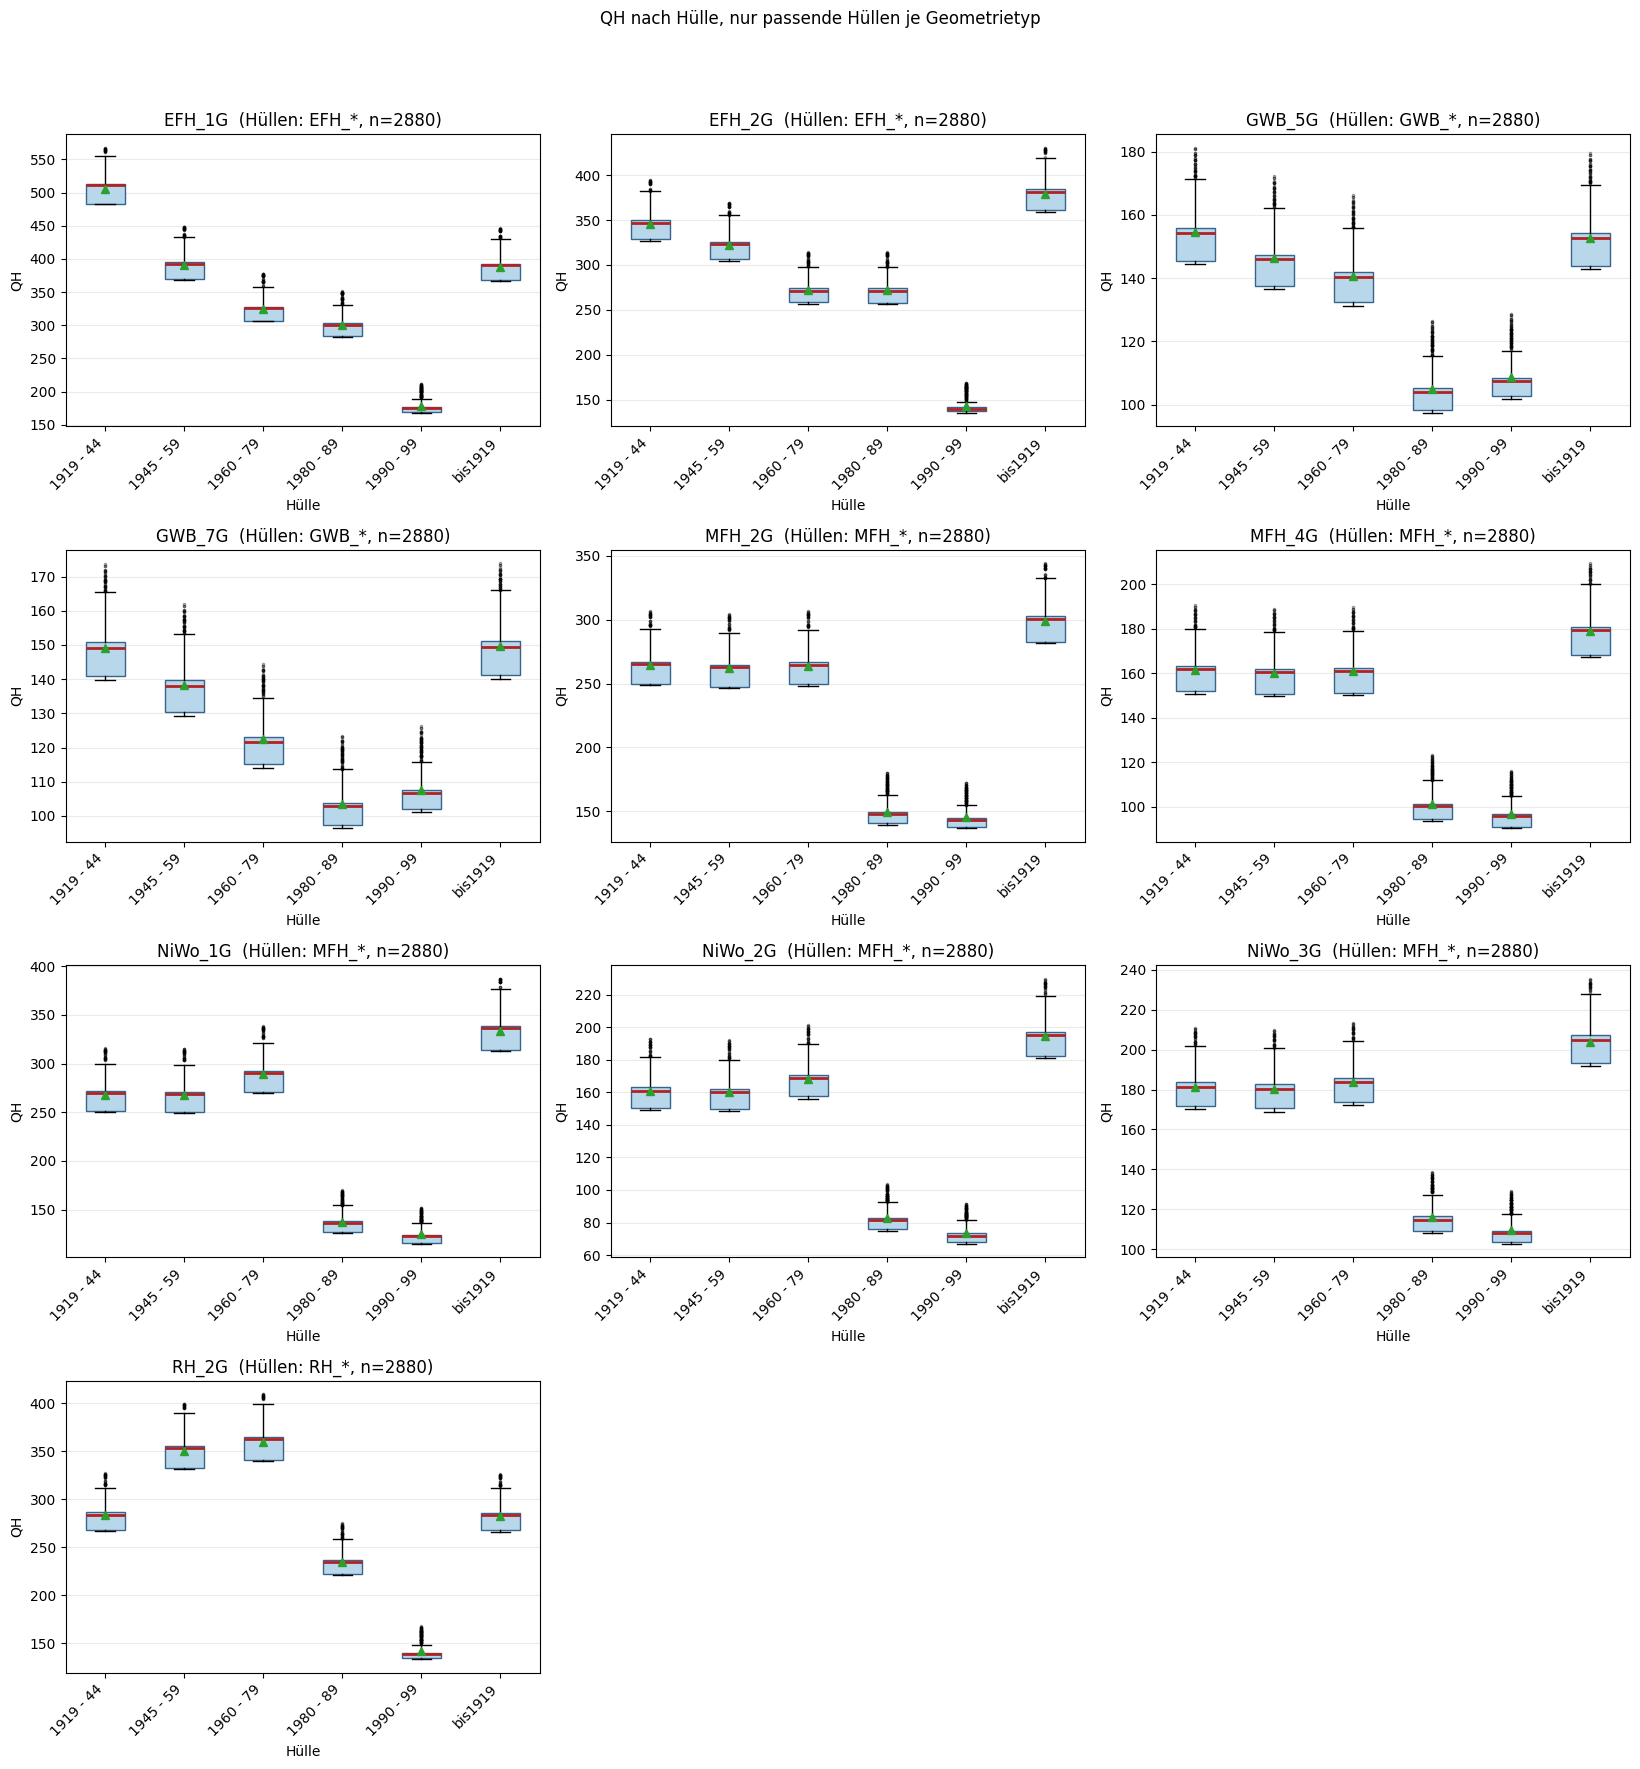

In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

datei = Path(r"C:\Users\ma0026.NB-MA0026\Documents\peexcel\data\building_typologies\building_sector_v3\scenarios_harmonisiert.parquet")

geo = "preset_recorded_geometry"
huelle = "preset_recorded_hulls"

# Abweichende Präfixe: Geometrie-Präfix -> Hüllen-Präfix
praefix_alias = {"NiWo": "MFH"}

def huellen_praefix(geometrie: str) -> str:
    p = geometrie.split("_", 1)[0]
    return praefix_alias.get(p, p) + "_"

df = pd.read_parquet(datei, columns=[geo, huelle, "QH"])
df["QH"] = pd.to_numeric(df["QH"], errors="raise")
df = df.dropna(subset=[geo, huelle, "QH"]).copy()
df[[geo, huelle]] = df[[geo, huelle]].astype("string")

# Nur passende Kombinationen behalten
passt = [
    h.startswith(huellen_praefix(g))
    for g, h in zip(df[geo], df[huelle])
]
verworfen = df.loc[[not p for p in passt], [geo, huelle]].drop_duplicates()
df = df.loc[passt]

typen = sorted(df[geo].unique())

# Kontrolle der Zuordnung
print("Geometrietyp -> Präfix -> Hüllen")
for t in typen:
    hs = sorted(df.loc[df[geo] == t, huelle].unique())
    print(f"{t} -> {huellen_praefix(t)} -> {hs}")
print(f"\nAusgeschlossene Kombinationen: {len(verworfen)}")

ohne_daten = set(pd.read_parquet(datei, columns=[geo])[geo].dropna().astype("string")) - set(typen)
if ohne_daten:
    print("Geometrietypen ohne passende Hülle:", sorted(ohne_daten))
if not typen:
    raise ValueError("Keine passenden Kombinationen gefunden. Präfixe prüfen.")

# Grafik
n_spalten = min(3, len(typen))
n_zeilen = (len(typen) + n_spalten - 1) // n_spalten

fig, achsen = plt.subplots(
    n_zeilen, n_spalten, squeeze=False,
    figsize=(5.5 * n_spalten, 4.5 * n_zeilen),
)

for ax, typ in zip(achsen.ravel(), typen):
    teil = df.loc[df[geo] == typ]
    huellen = sorted(teil[huelle].unique())
    gruppen = [teil.loc[teil[huelle] == h, "QH"].to_numpy() for h in huellen]

    ax.boxplot(
        gruppen, showmeans=True, patch_artist=True,
        boxprops=dict(facecolor="#b9d7ea", edgecolor="#36648b"),
        medianprops=dict(color="#b22222", linewidth=2),
        flierprops=dict(marker=".", markersize=3, alpha=0.4),
    )
    pre = huellen_praefix(typ)
    ax.set_xticks(range(1, len(huellen) + 1))
    ax.set_xticklabels([h.removeprefix(pre) for h in huellen],
                       rotation=45, ha="right")
    ax.set_title(f"{typ}  (Hüllen: {pre}*, n={len(teil)})")
    ax.set_xlabel("Hülle")
    ax.set_ylabel("QH")
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

for ax in achsen.ravel()[len(typen):]:
    ax.axis("off")

fig.suptitle("QH nach Hülle, nur passende Hüllen je Geometrietyp")
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()
# fig.savefig("QH_huelle_geometrietyp.png", dpi=200, bbox_inches="tight")

Geometrietyp -> Hüllen in Plot-Reihenfolge
EFH_1G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99']
EFH_2G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99']
GWB_5G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99']
GWB_7G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99']
MFH_2G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99']
MFH_4G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99']
NiWo_1G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99']
NiWo_2G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99']
NiWo_3G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99']
RH_2G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99']


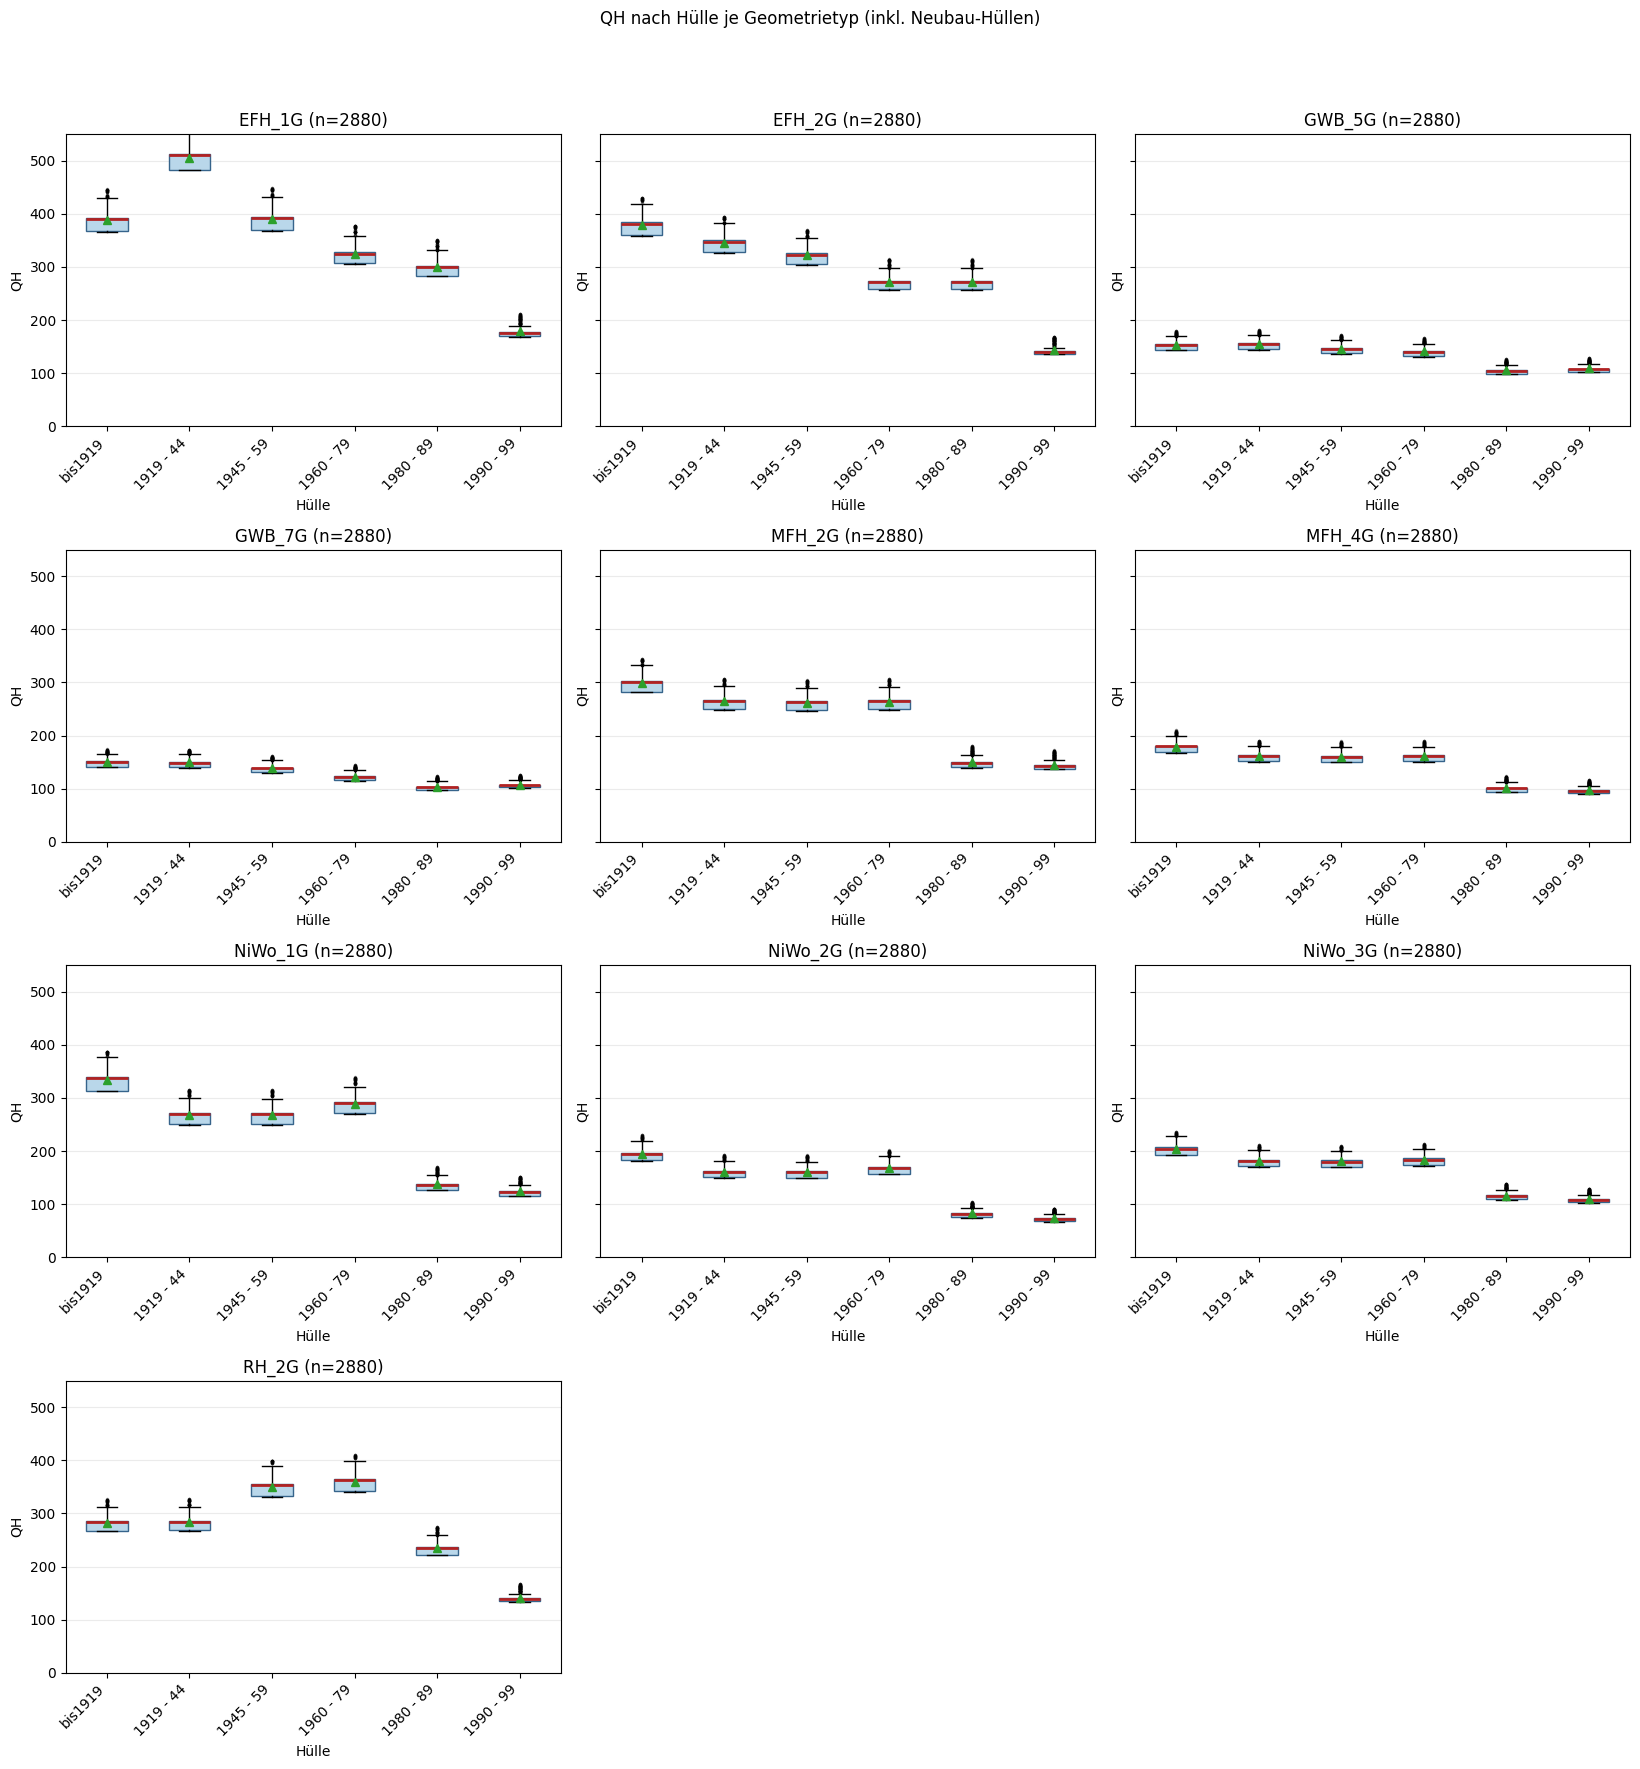

Werte außerhalb (0, 550): 33


In [4]:
import re
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

datei = Path(r"C:\Users\ma0026.NB-MA0026\Documents\peexcel\data\building_typologies\building_sector_v3\scenarios_harmonisiert.parquet")

geo = "preset_recorded_geometry"
huelle = "preset_recorded_hulls"
praefix_alias = {"NiWo": "MFH"}
y_grenzen = (0, 550)

def huellen_praefix(geometrie: str) -> str:
    p = geometrie.split("_", 1)[0]
    return praefix_alias.get(p, p) + "_"

import re

neubau_huellen = ["WD1", "WD2", "WD3"]
neubau_label = {"WD1": "Neubau 10cm", "WD2": "Neubau 20cm", "WD3": "Neubau 30cm"}
# Annahme: WD1 = 10 cm, WD2 = 20 cm, WD3 = 30 cm. Bitte prüfen.

def ist_neubau(h: str, pre: str = "") -> bool:
    return h in neubau_huellen

def kurzname(h: str, pre: str) -> str:
    return neubau_label.get(h, h.removeprefix(pre))

def sortierschluessel(h: str, pre: str):
    if ist_neubau(h):
        return (2, neubau_huellen.index(h), h)
    name = h.removeprefix(pre).lower()
    zahl = re.search(r"\d+", name)
    zahl = int(zahl.group()) if zahl else 0
    return (0 if name.startswith("bis") else 1, zahl, name)


df = pd.read_parquet(datei, columns=[geo, huelle, "QH"])
df["QH"] = pd.to_numeric(df["QH"], errors="raise")
df = df.dropna(subset=[geo, huelle, "QH"]).copy()
df[[geo, huelle]] = df[[geo, huelle]].astype("string")

# Filter: passendes Präfix ODER Neubau-Hülle
behalten = [
    h.startswith(huellen_praefix(g)) or ist_neubau(h)
    for g, h in zip(df[geo], df[huelle])
]
df = df.loc[behalten]
typen = sorted(df[geo].unique())

print("Geometrietyp -> Hüllen in Plot-Reihenfolge")
for t in typen:
    pre = huellen_praefix(t)
    hs = sorted(df.loc[df[geo] == t, huelle].unique(),
                key=lambda h: sortierschluessel(h, pre))
    print(f"{t}: {[kurzname(h, pre) for h in hs]}")
if not typen:
    raise ValueError("Keine passenden Kombinationen gefunden. Präfixe prüfen.")

n_spalten = min(3, len(typen))
n_zeilen = (len(typen) + n_spalten - 1) // n_spalten
fig, achsen = plt.subplots(
    n_zeilen, n_spalten, sharey=True, squeeze=False,
    figsize=(5.5 * n_spalten, 4.5 * n_zeilen),
)

for ax, typ in zip(achsen.ravel(), typen):
    pre = huellen_praefix(typ)
    teil = df.loc[df[geo] == typ]
    huellen = sorted(teil[huelle].unique(),
                     key=lambda h: sortierschluessel(h, pre))
    gruppen = [teil.loc[teil[huelle] == h, "QH"].to_numpy() for h in huellen]

    ax.boxplot(
        gruppen, showmeans=True, patch_artist=True,
        boxprops=dict(facecolor="#b9d7ea", edgecolor="#36648b"),
        medianprops=dict(color="#b22222", linewidth=2),
        flierprops=dict(marker=".", markersize=3, alpha=0.4),
    )
    ax.set_xticks(range(1, len(huellen) + 1))
    ax.set_xticklabels([kurzname(h, pre) for h in huellen],
                       rotation=45, ha="right")
    ax.set_ylim(*y_grenzen)
    ax.set_title(f"{typ} (n={len(teil)})")
    ax.set_xlabel("Hülle")
    ax.set_ylabel("QH")
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

for ax in achsen.ravel()[len(typen):]:
    ax.axis("off")

fig.suptitle("QH nach Hülle je Geometrietyp (inkl. Neubau-Hüllen)")
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

ausserhalb = (df["QH"] < y_grenzen[0]) | (df["QH"] > y_grenzen[1])
print(f"Werte außerhalb {y_grenzen}: {int(ausserhalb.sum())}")
# fig.savefig("QH_huelle_geometrietyp.png", dpi=200, bbox_inches="tight")

Geometrietyp -> Hüllen in Plot-Reihenfolge
EFH_1G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99', 'WD1 (1/3, 10cm)', 'WD2 (2/3, 20cm)', 'WD3 (3/3, 30cm)']
EFH_2G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99', 'WD1 (1/3, 10cm)', 'WD2 (2/3, 20cm)', 'WD3 (3/3, 30cm)']
GWB_5G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99', 'WD1 (1/3, 10cm)', 'WD2 (2/3, 20cm)', 'WD3 (3/3, 30cm)']
GWB_7G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99', 'WD1 (1/3, 10cm)', 'WD2 (2/3, 20cm)', 'WD3 (3/3, 30cm)']
MFH_2G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99', 'WD1 (1/3, 10cm)', 'WD2 (2/3, 20cm)', 'WD3 (3/3, 30cm)']
MFH_4G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99', 'WD1 (1/3, 10cm)', 'WD2 (2/3, 20cm)', 'WD3 (3/3, 30cm)']
NiWo_1G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99', 'WD1 (1/3, 10cm)', 

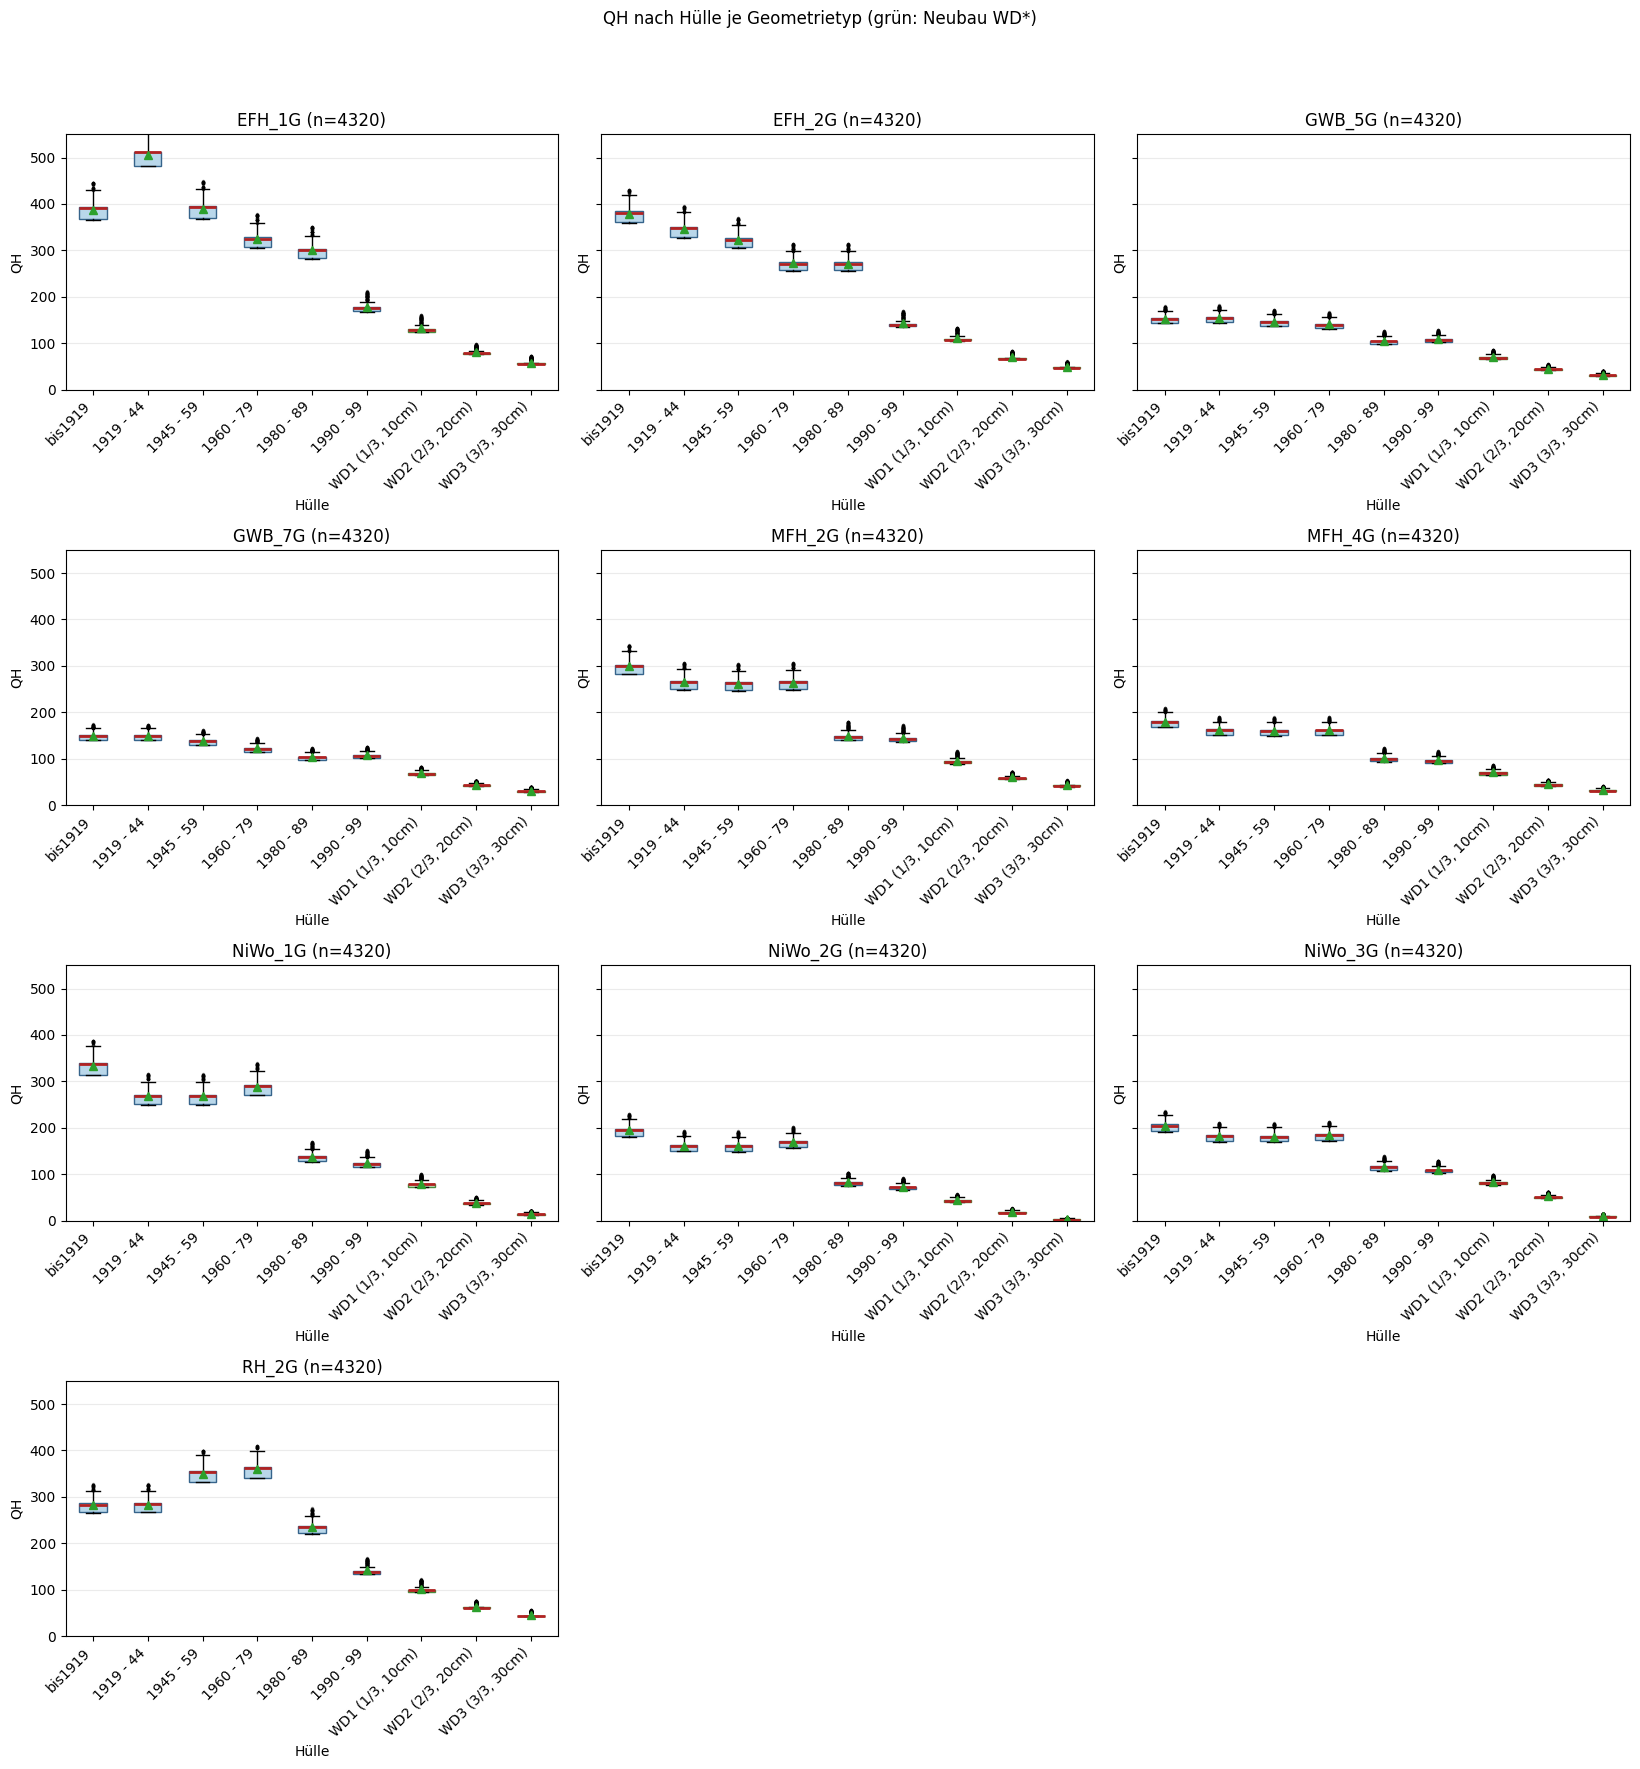

Werte außerhalb (0, 550): 33


In [5]:
import re
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# ── Einstellungen ────────────────────────────────────────────────────
datei = Path(r"C:\Users\ma0026.NB-MA0026\Documents\peexcel\data\building_typologies\building_sector_v3\scenarios_harmonisiert.parquet")

geo = "preset_recorded_geometry"
huelle = "preset_recorded_hulls"
wert = "QH"

praefix_alias = {"NiWo": "MFH"}      # Geometrie-Präfix -> Hüllen-Präfix
y_grenzen = (0, 550)
neubau_muster = re.compile(r"^(?:[A-Za-z]+_)?WD\d*", re.IGNORECASE)
neubau_label = {}                    # optional, z. B. {"WD1": "WD1 (10 cm)"}

# ── Hilfsfunktionen ──────────────────────────────────────────────────
def huellen_praefix(geometrie: str) -> str:
    p = geometrie.split("_", 1)[0]
    return praefix_alias.get(p, p) + "_"

def ist_neubau(h: str) -> bool:
    return neubau_muster.match(h) is not None

def kurzname(h: str, pre: str) -> str:
    name = h.removeprefix(pre)
    return neubau_label.get(name, name)

def sortierschluessel(h: str, pre: str):
    name = h.removeprefix(pre).lower()
    zahl = re.search(r"\d+", name)
    zahl = int(zahl.group()) if zahl else 0
    if name.startswith("bis"):
        gruppe = 0
    elif ist_neubau(h):
        gruppe = 2
    else:
        gruppe = 1
    return (gruppe, zahl, name)

# ── Daten laden ──────────────────────────────────────────────────────
df = pd.read_parquet(datei, columns=[geo, huelle, wert])
df[wert] = pd.to_numeric(df[wert], errors="raise")
df = df.dropna(subset=[geo, huelle, wert]).copy()
df[[geo, huelle]] = df[[geo, huelle]].astype("string")

# Passendes Präfix ODER Neubau-Hülle (WD*)
behalten = [
    h.startswith(huellen_praefix(g)) or ist_neubau(h)
    for g, h in zip(df[geo], df[huelle])
]
df = df.loc[behalten]
typen = sorted(df[geo].unique())

if not typen:
    raise ValueError("Keine passenden Kombinationen gefunden. Präfixe prüfen.")

# Kontrolle der Zuordnung
print("Geometrietyp -> Hüllen in Plot-Reihenfolge")
for t in typen:
    pre = huellen_praefix(t)
    hs = sorted(df.loc[df[geo] == t, huelle].unique(),
                key=lambda h: sortierschluessel(h, pre))
    print(f"{t}: {[kurzname(h, pre) for h in hs]}")

# ── Grafik ───────────────────────────────────────────────────────────
n_spalten = min(3, len(typen))
n_zeilen = (len(typen) + n_spalten - 1) // n_spalten

fig, achsen = plt.subplots(
    n_zeilen, n_spalten, sharey=True, squeeze=False,
    figsize=(5.5 * n_spalten, 4.5 * n_zeilen),
)

for ax, typ in zip(achsen.ravel(), typen):
    pre = huellen_praefix(typ)
    teil = df.loc[df[geo] == typ]
    huellen = sorted(teil[huelle].unique(),
                     key=lambda h: sortierschluessel(h, pre))
    gruppen = [teil.loc[teil[huelle] == h, wert].to_numpy() for h in huellen]

    ax.boxplot(
        gruppen, showmeans=True, patch_artist=True,
        boxprops=dict(facecolor="#b9d7ea", edgecolor="#36648b"),
        medianprops=dict(color="#b22222", linewidth=2),
        flierprops=dict(marker=".", markersize=3, alpha=0.4),
    )

    # Neubau-Boxen farblich absetzen
    for box, h in zip(ax.patches, huellen):
        if ist_neubau(h):
            box.set_facecolor("#c9e4c5")
            box.set_edgecolor("#4b8a3f")

    ax.set_xticks(range(1, len(huellen) + 1))
    ax.set_xticklabels([kurzname(h, pre) for h in huellen],
                       rotation=45, ha="right")
    ax.set_ylim(*y_grenzen)
    ax.set_title(f"{typ} (n={len(teil)})")
    ax.set_xlabel("Hülle")
    ax.set_ylabel(wert)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

for ax in achsen.ravel()[len(typen):]:
    ax.axis("off")

fig.suptitle("QH nach Hülle je Geometrietyp (grün: Neubau WD*)")
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

ausserhalb = (df[wert] < y_grenzen[0]) | (df[wert] > y_grenzen[1])
print(f"Werte außerhalb {y_grenzen}: {int(ausserhalb.sum())}")
# fig.savefig("QH_huelle_geometrietyp.png", dpi=200, bbox_inches="tight")

Geometrieklasse -> enthaltene Geometrietypen
EFH: ['EFH_1G', 'EFH_2G']
RH: ['RH_2G']
MFH: ['MFH_2G', 'MFH_4G']
GWB: ['GWB_5G', 'GWB_7G']
NiWo: ['NiWo_1G', 'NiWo_2G', 'NiWo_3G']


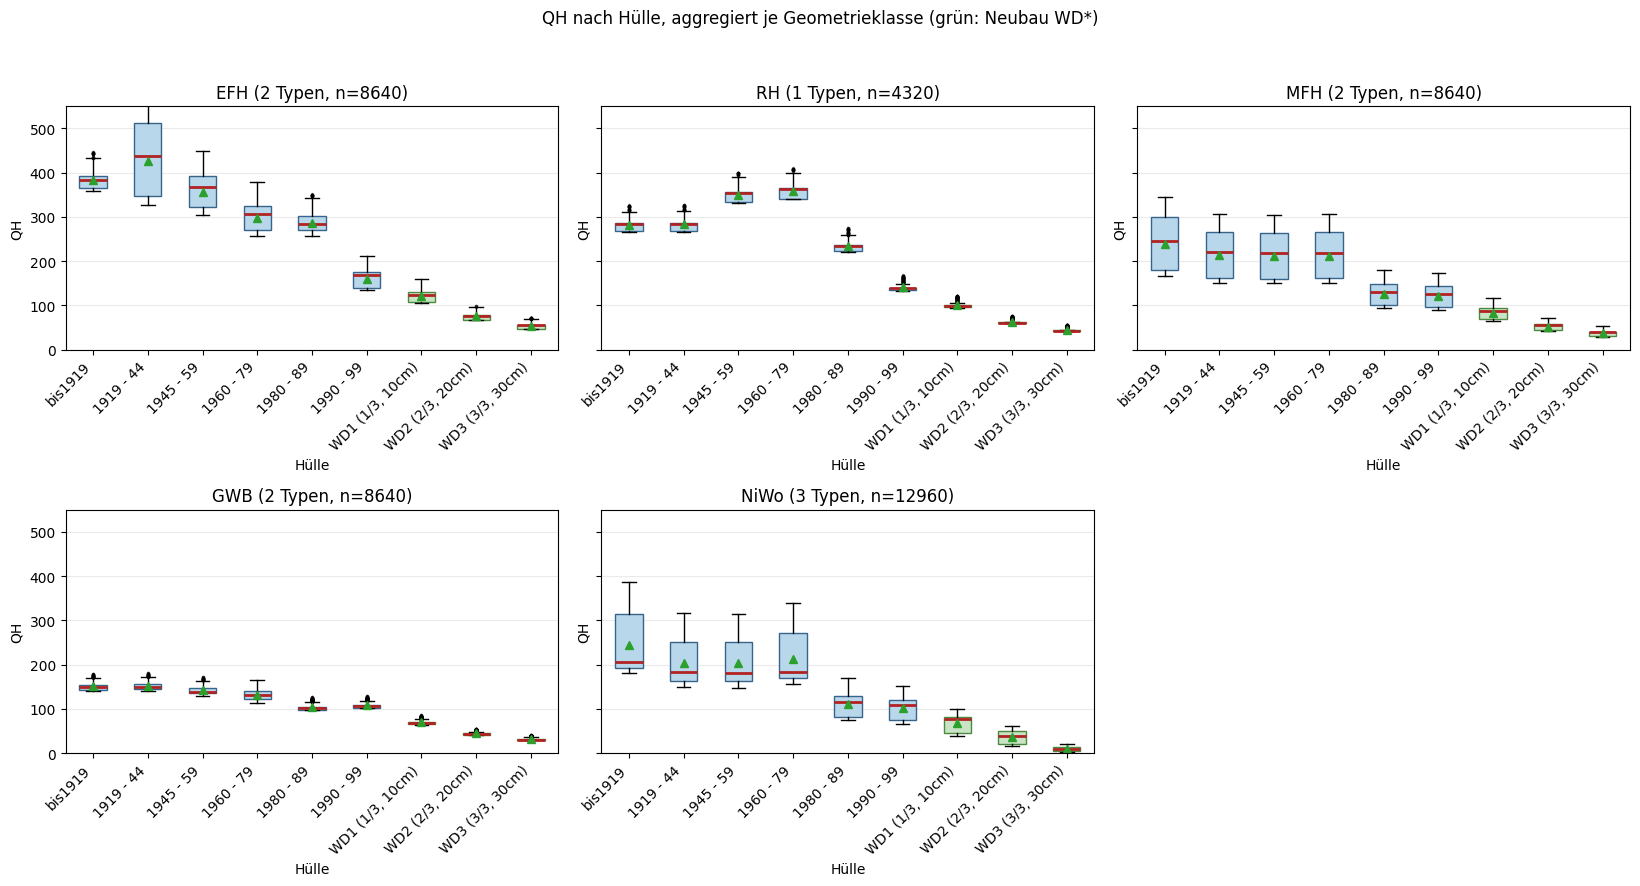

In [6]:
klassen_reihenfolge = ["EFH", "RH", "MFH", "GWB", "NiWo"]

agg = df.copy()
agg["geometrieklasse"] = agg[geo].str.split("_", n=1).str[0]

vorhanden = agg["geometrieklasse"].unique().tolist()
klassen = (
    [k for k in klassen_reihenfolge if k in vorhanden]
    + sorted(set(vorhanden) - set(klassen_reihenfolge))
)

print("Geometrieklasse -> enthaltene Geometrietypen")
for k in klassen:
    print(f"{k}: {sorted(agg.loc[agg['geometrieklasse'] == k, geo].unique())}")

n_spalten = min(3, len(klassen))
n_zeilen = (len(klassen) + n_spalten - 1) // n_spalten

fig, achsen = plt.subplots(
    n_zeilen, n_spalten, sharey=True, squeeze=False,
    figsize=(5.5 * n_spalten, 4.5 * n_zeilen),
)

for ax, klasse in zip(achsen.ravel(), klassen):
    pre = praefix_alias.get(klasse, klasse) + "_"
    teil = agg.loc[agg["geometrieklasse"] == klasse]
    huellen = sorted(teil[huelle].unique(),
                     key=lambda h: sortierschluessel(h, pre))
    gruppen = [teil.loc[teil[huelle] == h, wert].to_numpy() for h in huellen]

    ax.boxplot(
        gruppen, showmeans=True, patch_artist=True,
        boxprops=dict(facecolor="#b9d7ea", edgecolor="#36648b"),
        medianprops=dict(color="#b22222", linewidth=2),
        flierprops=dict(marker=".", markersize=3, alpha=0.4),
    )

    for box, h in zip(ax.patches, huellen):
        if ist_neubau(h):
            box.set_facecolor("#c9e4c5")
            box.set_edgecolor("#4b8a3f")

    n_typen = teil[geo].nunique()
    ax.set_xticks(range(1, len(huellen) + 1))
    ax.set_xticklabels([kurzname(h, pre) for h in huellen],
                       rotation=45, ha="right")
    ax.set_ylim(*y_grenzen)
    ax.set_title(f"{klasse} ({n_typen} Typen, n={len(teil)})")
    ax.set_xlabel("Hülle")
    ax.set_ylabel(wert)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

for ax in achsen.ravel()[len(klassen):]:
    ax.axis("off")

fig.suptitle("QH nach Hülle, aggregiert je Geometrieklasse (grün: Neubau WD*)")
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()
# fig.savefig("QH_huelle_geometrieklasse.png", dpi=200, bbox_inches="tight")

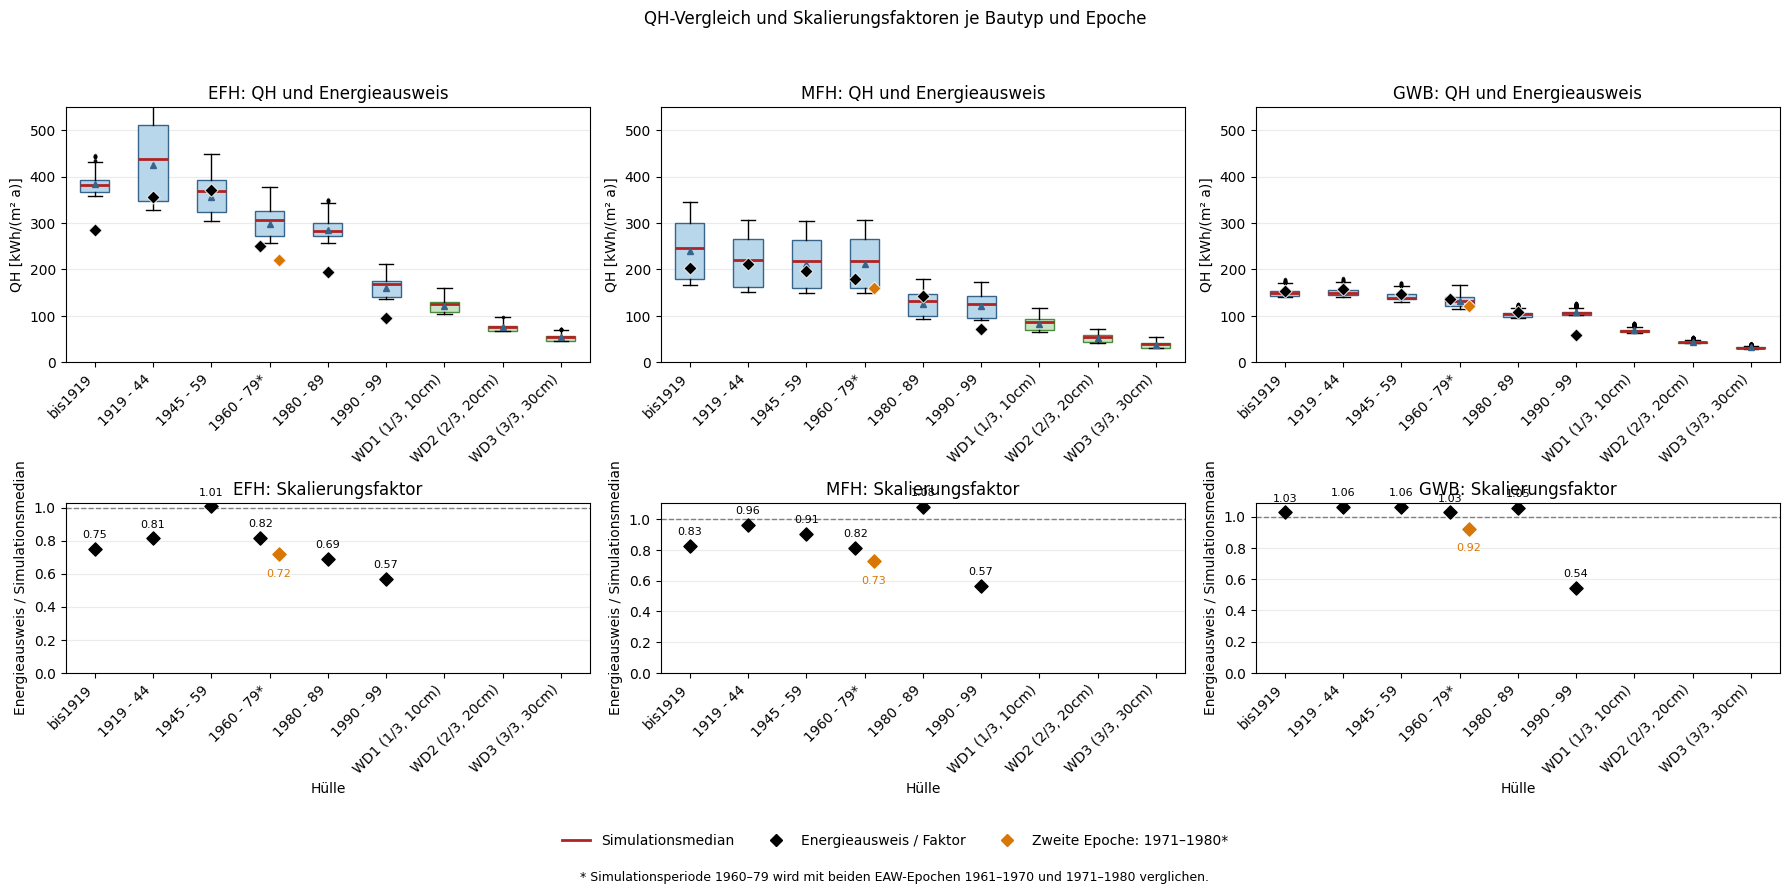

,Bautyp,Huelle,Referenzepoche,Doppelte_Zuordnung,Anzahl_Simulationen,QH_Simulation_Median,QH_EAW,Skalierungsfaktor
0,EFH,EFH_bis1919,Vor 1919,False,960,382.61,286.125,0.748
1,EFH,EFH_1919 - 44,1919 bis 1944,False,960,438.45,356.625,0.813
2,EFH,EFH_1945 - 59,1945 bis 1960,False,960,368.27,370.750,1.007
3,EFH,EFH_1960 - 79,1961 bis 1970,True,960,305.67,249.625,0.817
4,EFH,EFH_1960 - 79,1971 bis 1980,True,960,305.67,219.625,0.718
5,EFH,EFH_1980 - 89,1981 bis 1990,False,960,282.90,195.375,0.691
6,EFH,EFH_1990 - 99,1991 bis 2000,False,960,167.98,95.750,0.570
7,MFH,MFH_bis1919,Vor 1919,False,960,245.47,202.750,0.826
8,MFH,MFH_1919 - 44,1919 bis 1944,False,960,219.56,211.375,0.963
9,MFH,MFH_1945 - 59,1945 bis 1960,False,960,217.63,197.375,0.907


In [9]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Voraussetzung aus den bisherigen Zellen:
# df, geo, huelle, wert, referenz,
# praefix_alias, ist_neubau, kurzname, sortierschluessel
#
# referenz enthält bereits die mit 1.25 multiplizierten Werte
# mit Index "Epoche" und Spalten EFH, MFH, GWB.

# ── Epochenzuordnung ──────────────────────────────────────────────────
# Leerzeichen werden beim Abgleich ignoriert.
def norm(text):
    return re.sub(r"\s+", "", str(text)).casefold()

epoche_mapping = {
    "bis 1919": ["Vor 1919"],
    "vor1919": ["Vor 1919"],
    "1919 - 44": ["1919 bis 1944"],
    "1945 - 59": ["1945 bis 1960"],
    "1960 - 79": ["1961 bis 1970", "1971 bis 1980"],
    "1980 - 89": ["1981 bis 1990"],
    "1990 - 99": ["1991 bis 2000"],
}
epoche_mapping = {
    norm(k): v for k, v in epoche_mapping.items()
}

def referenzepochen(h, pre):
    name = str(h).removeprefix(pre)
    return epoche_mapping.get(norm(name), [])

# ── Geometrieklassen bilden ───────────────────────────────────────────
agg = df.copy()
agg["geometrieklasse"] = agg[geo].str.split("_", n=1).str[0]
agg[wert] = pd.to_numeric(agg[wert], errors="raise")
agg = agg.dropna(subset=[geo, huelle, wert])

# Nur Klassen mit vorhandenen Referenzwerten
klassen = [
    k for k in ["EFH", "MFH", "GWB"]
    if k in set(agg["geometrieklasse"]) and k in referenz.columns
]
if not klassen:
    raise ValueError("Keine passenden Klassen mit Referenzwerten vorhanden.")

fig, achsen = plt.subplots(
    2, len(klassen),
    squeeze=False,
    figsize=(6 * len(klassen), 9),
    gridspec_kw={"height_ratios": [1.5, 1]},
)

ergebnisse = []
ohne_zuordnung = set()

for sp, klasse in enumerate(klassen):
    ax_qh = achsen[0, sp]
    ax_f = achsen[1, sp]

    pre = praefix_alias.get(klasse, klasse) + "_"
    teil = agg.loc[agg["geometrieklasse"] == klasse]

    huellen = sorted(
        teil[huelle].unique(),
        key=lambda h: sortierschluessel(h, pre),
    )

    gruppen = [
        teil.loc[teil[huelle] == h, wert].to_numpy(dtype=float)
        for h in huellen
    ]

    # ── Oben: Simulation als Boxplot ──────────────────────────────────
    boxen = ax_qh.boxplot(
        gruppen,
        patch_artist=True,
        showmeans=True,
        boxprops=dict(facecolor="#b9d7ea", edgecolor="#36648b"),
        medianprops=dict(color="#b22222", linewidth=2),
        meanprops=dict(
            marker="^", markerfacecolor="#36648b",
            markeredgecolor="#36648b", markersize=4,
        ),
        flierprops=dict(marker=".", markersize=3, alpha=0.35),
    )

    for box, h in zip(boxen["boxes"], huellen):
        if ist_neubau(h):
            box.set_facecolor("#c9e4c5")
            box.set_edgecolor("#4b8a3f")

    labels = []

    for position, (h, werte) in enumerate(zip(huellen, gruppen), start=1):
        epochen = referenzepochen(h, pre)
        mehrfach = len(epochen) > 1

        labels.append(kurzname(h, pre) + ("*" if mehrfach else ""))

        if not epochen:
            if not ist_neubau(h):
                ohne_zuordnung.add((klasse, h))
            continue

        median = float(np.median(werte))

        # Zwei Referenzen derselben Periode leicht horizontal versetzen
        offsets = [-0.16, 0.16] if mehrfach else [0.0]

        for epoche, offset in zip(epochen, offsets):
            ref_wert = float(referenz.at[epoche, klasse])
            faktor = ref_wert / median if median != 0 else np.nan
            x = position + offset

            # Unterschiedliche Farbe für die zweite Referenz
            zweite_referenz = mehrfach and offset > 0
            farbe = "#d97706" if zweite_referenz else "black"

            ax_qh.scatter(
                x, ref_wert,
                marker="D", s=45, color=farbe,
                edgecolors="white", linewidths=0.6, zorder=5,
            )

            if np.isfinite(faktor):
                ax_f.scatter(
                    x, faktor,
                    marker="D", s=45, color=farbe, zorder=5,
                )
                ax_f.annotate(
                    f"{faktor:.2f}",
                    (x, faktor),
                    xytext=(0, 8 if not zweite_referenz else -16),
                    textcoords="offset points",
                    ha="center", fontsize=8,
                    color=farbe,
                )

            ergebnisse.append({
                "Bautyp": klasse,
                "Huelle": h,
                "Referenzepoche": epoche,
                "Doppelte_Zuordnung": mehrfach,
                "Anzahl_Simulationen": len(werte),
                "QH_Simulation_Median": median,
                "QH_EAW": ref_wert,
                "Skalierungsfaktor": faktor,
            })

    # ── Achsen formatieren ────────────────────────────────────────────
    for ax in (ax_qh, ax_f):
        ax.set_xticks(range(1, len(huellen) + 1))
        ax.set_xticklabels(labels, rotation=45, ha="right")
        ax.set_xlim(0.5, len(huellen) + 0.5)
        ax.grid(axis="y", alpha=0.25)
        ax.set_axisbelow(True)

    ax_qh.set_ylim(0, 550)
    ax_qh.set_title(f"{klasse}: QH und Energieausweis")
    ax_qh.set_ylabel("QH [kWh/(m² a)]")

    ax_f.axhline(1, color="gray", linestyle="--", linewidth=1)
    ax_f.set_ylim(bottom=0)
    ax_f.margins(y=0.2)
    ax_f.set_title(f"{klasse}: Skalierungsfaktor")
    ax_f.set_ylabel("Energieausweis / Simulationsmedian")
    ax_f.set_xlabel("Hülle")

legende = [
    Line2D(
        [0], [0], color="#b22222", linewidth=2,
        label="Simulationsmedian",
    ),
    Line2D(
        [0], [0], marker="D", color="black", linestyle="None",
        label="Energieausweis / Faktor",
    ),
    Line2D(
        [0], [0], marker="D", color="#d97706", linestyle="None",
        label="Zweite Epoche: 1971–1980*",
    ),
]

fig.suptitle("QH-Vergleich und Skalierungsfaktoren je Bautyp und Epoche")
fig.legend(
    handles=legende, loc="lower center",
    bbox_to_anchor=(0.5, 0.035), ncol=3, frameon=False,
)
fig.text(
    0.5, 0.012,
    "* Simulationsperiode 1960–79 wird mit beiden EAW-Epochen "
    "1961–1970 und 1971–1980 verglichen.",
    ha="center", fontsize=9,
)
fig.tight_layout(rect=[0, 0.09, 1, 0.95])
plt.show()

# ── Ergebnistabelle ───────────────────────────────────────────────────
skalierungsfaktoren = pd.DataFrame(ergebnisse)

display(
    skalierungsfaktoren.round({
        "QH_Simulation_Median": 2,
        "QH_EAW-Default": 2,
        "Skalierungsfaktor": 3,
    })
)

if ohne_zuordnung:
    print("\nKeine Referenzzuordnung für:")
    for klasse, h in sorted(ohne_zuordnung):
        print(f"  {klasse}: {h!r}")

# Optional speichern:
# skalierungsfaktoren.to_csv(
#     "QH_skalierungsfaktoren.csv", index=False, sep=";", decimal=","
# )
# fig.savefig("QH_skalierungsfaktoren.png", dpi=200, bbox_inches="tight")

Zeilen ohne gültige Geometrie, Hülle oder QH: 0
Zeilen mit unpassendem Hüllenpräfix: 0


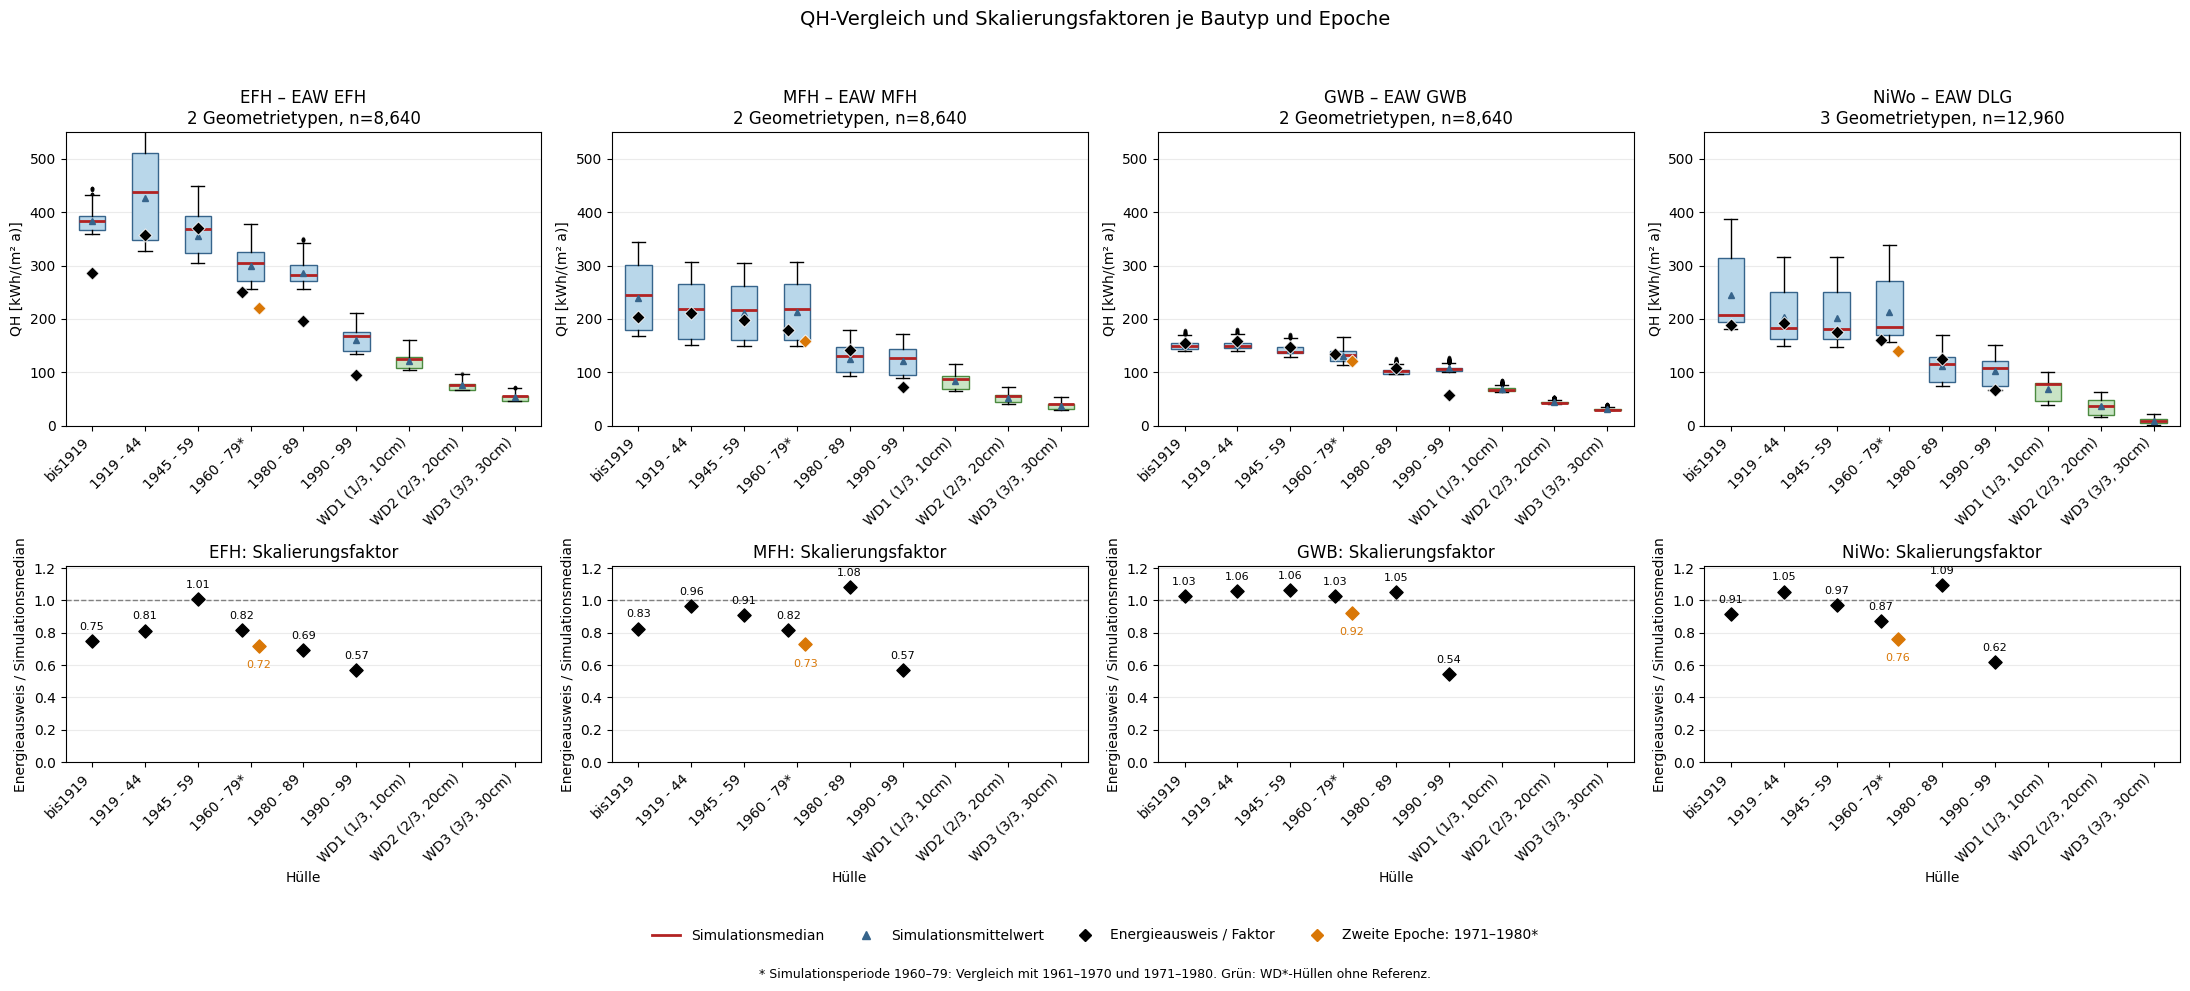

,Bautyp,Huelle,Referenzepoche,Doppelte_Zuordnung,Anzahl_Simulationen,QH_Simulation_Median,QH_EAW,Skalierungsfaktor
0,EFH,EFH_bis1919,Vor 1919,False,960,382.61,286.12,0.748
1,EFH,EFH_1919 - 44,1919 bis 1944,False,960,438.45,356.62,0.813
2,EFH,EFH_1945 - 59,1945 bis 1960,False,960,368.27,370.75,1.007
3,EFH,EFH_1960 - 79,1961 bis 1970,True,960,305.67,249.62,0.817
4,EFH,EFH_1960 - 79,1971 bis 1980,True,960,305.67,219.62,0.718
5,EFH,EFH_1980 - 89,1981 bis 1990,False,960,282.90,195.38,0.691
6,EFH,EFH_1990 - 99,1991 bis 2000,False,960,167.98,95.75,0.570
7,MFH,MFH_bis1919,Vor 1919,False,960,245.47,202.75,0.826
8,MFH,MFH_1919 - 44,1919 bis 1944,False,960,219.56,211.38,0.963
9,MFH,MFH_1945 - 59,1945 bis 1960,False,960,217.63,197.38,0.907



Undefinierte Faktoren wegen Simulationsmedian = 0: 0
QH-Werte außerhalb der dargestellten Skala: 33


In [12]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

# ── Einstellungen ────────────────────────────────────────────────────
datei = Path(r"C:\Users\ma0026.NB-MA0026\Documents\peexcel\data\building_typologies\building_sector_v3\scenarios_harmonisiert.parquet")

geo = "preset_recorded_geometry"
huelle = "preset_recorded_hulls"
wert = "QH"

referenz_faktor = 1.25
qh_grenzen = (0, 550)
klassen_reihenfolge = ["EFH", "MFH", "GWB", "NiWo"]

# NiWo verwendet MFH-Hüllen, aber eigene DLG-Referenzwerte
huellen_praefix = {
    "EFH": "EFH_",
    "MFH": "MFH_",
    "GWB": "GWB_",
    "NiWo": "MFH_",
}

# Optional speichern
speichern = False
ausgabeordner = datei.parent / "QH_Analyse"

# ── Referenzen: unveränderte Ausgangswerte ─────────────────────────────
referenz = pd.DataFrame({
    "Epoche": [
        "Vor 1919",
        "1919 bis 1944",
        "1945 bis 1960",
        "1961 bis 1970",
        "1971 bis 1980",
        "1981 bis 1990",
        "1991 bis 2000",
        "2001 bis 2010",
    ],
    "EFH": [
        228.9, 285.3, 296.6, 199.7,
        175.7, 156.3, 76.6, 80.3,
    ],
    "MFH": [
        162.2, 169.1, 157.9, 142.9,
        127.4, 113.5, 57.5, 60.0,
    ],
    "GWB": [
        123.3, 126.9, 117.8, 108.2,
        97.2, 86.8, 46.5, 47.9,
    ],
    "NiWo": [
        151.3, 153.9, 140.8, 128.4,
        112.5, 100.4, 53.7, 55.2,
    ],
}).set_index("Epoche")

referenz = referenz * referenz_faktor

# ── Hilfsfunktionen und Epochenzuordnung ───────────────────────────────
def norm(text):
    """Leerzeichen und unterschiedliche Bindestriche vereinheitlichen."""
    text = str(text).strip().casefold()
    text = text.replace("–", "-").replace("—", "-")
    return re.sub(r"\s+", "", text)


def ohne_praefix(name):
    """Bekannte Gebäudepräfixe entfernen, auch für WD-Hüllen."""
    return re.sub(
        r"^(?:EFH|RH|MFH|GWB|NiWo)_",
        "",
        str(name).strip(),
        flags=re.IGNORECASE,
    )


def ist_neubau(name):
    # WD*: z. B. WD1, WD2, WD3 oder MFH_WD1
    return ohne_praefix(name).casefold().startswith("wd")


epoche_mapping = {
    "bis 1919": ["Vor 1919"],
    "vor 1919": ["Vor 1919"],
    "1919 - 44": ["1919 bis 1944"],
    "1945 - 59": ["1945 bis 1960"],
    "1960 - 79": ["1961 bis 1970", "1971 bis 1980"],
    "1980 - 89": ["1981 bis 1990"],
    "1990 - 99": ["1991 bis 2000"],
}

# Exakte Referenzbezeichnungen ebenfalls akzeptieren
for epoche in referenz.index:
    epoche_mapping.setdefault(epoche, [epoche])

epoche_mapping = {
    norm(name): epochen
    for name, epochen in epoche_mapping.items()
}


def referenzepochen(name):
    return epoche_mapping.get(norm(ohne_praefix(name)), [])


def sortierschluessel(name):
    kurz = ohne_praefix(name)
    normalisiert = norm(kurz)
    zahl = re.search(r"\d+", kurz)
    zahl = int(zahl.group()) if zahl else 9999

    if ist_neubau(name):
        return (2, zahl, normalisiert)

    if normalisiert.startswith(("bis", "vor")):
        return (0, zahl, normalisiert)

    return (1, zahl, normalisiert)


# ── Daten einlesen ────────────────────────────────────────────────────
df = pd.read_parquet(datei, columns=[geo, huelle, wert])
df[wert] = pd.to_numeric(df[wert], errors="raise")

n_vorher = len(df)
df = df.dropna(subset=[geo, huelle, wert]).copy()
df = df.loc[np.isfinite(df[wert])].copy()

print(f"Zeilen ohne gültige Geometrie, Hülle oder QH: {n_vorher - len(df):,}")

df[geo] = df[geo].astype("string").str.strip()
df[huelle] = df[huelle].astype("string").str.strip()

# Geometrieklasse: z. B. EFH_1G -> EFH
klassen_alias = {k.casefold(): k for k in klassen_reihenfolge}
df["geometrieklasse"] = (
    df[geo]
    .str.split("_", n=1)
    .str[0]
    .str.casefold()
    .map(klassen_alias)
)

df = df.loc[df["geometrieklasse"].notna()].copy()

# Passende Präfix-Hüllen plus WD* ohne Gebäudepräfix.
# Bei präfixierten WD-Hüllen muss das Präfix ebenfalls passen.
def passende_huelle(klasse, name):
    name = str(name).strip()
    pre = huellen_praefix[klasse]

    return (
        name.casefold().startswith(pre.casefold())
        or name.casefold().startswith("wd")
    )


behalten = [
    passende_huelle(k, h)
    for k, h in zip(df["geometrieklasse"], df[huelle])
]

print(f"Zeilen mit unpassendem Hüllenpräfix: {len(df) - sum(behalten):,}")
agg = df.loc[behalten].copy()

klassen = [
    k for k in klassen_reihenfolge
    if k in set(agg["geometrieklasse"])
]

if not klassen:
    raise ValueError("Keine passenden Daten für EFH, MFH, GWB oder NiWo.")

# ── Grafik: oben QH, unten Faktoren ────────────────────────────────────
fig, achsen = plt.subplots(
    2,
    len(klassen),
    squeeze=False,
    figsize=(5.5 * len(klassen), 10),
    gridspec_kw={"height_ratios": [1.5, 1]},
)

ergebnisse = []
ohne_zuordnung = set()

for sp, klasse in enumerate(klassen):
    ax_qh = achsen[0, sp]
    ax_f = achsen[1, sp]

    teil = agg.loc[agg["geometrieklasse"] == klasse]
    huellen = sorted(
        teil[huelle].unique(),
        key=sortierschluessel,
    )

    gruppen = [
        teil.loc[teil[huelle] == h, wert].to_numpy(dtype=float)
        for h in huellen
    ]

    boxen = ax_qh.boxplot(
        gruppen,
        patch_artist=True,
        showmeans=True,
        boxprops=dict(facecolor="#b9d7ea", edgecolor="#36648b"),
        medianprops=dict(color="#b22222", linewidth=2),
        meanprops=dict(
            marker="^",
            markerfacecolor="#36648b",
            markeredgecolor="#36648b",
            markersize=4,
        ),
        flierprops=dict(marker=".", markersize=3, alpha=0.35),
    )

    for box, h in zip(boxen["boxes"], huellen):
        if ist_neubau(h):
            box.set_facecolor("#c9e4c5")
            box.set_edgecolor("#4b8a3f")

    labels = []

    for position, (h, werte) in enumerate(zip(huellen, gruppen), start=1):
        epochen = [] if ist_neubau(h) else referenzepochen(h)
        doppelt = len(epochen) > 1

        labels.append(ohne_praefix(h) + ("*" if doppelt else ""))

        if not epochen:
            if not ist_neubau(h):
                ohne_zuordnung.add((klasse, h))
            continue

        median = float(np.median(werte))
        offsets = [-0.16, 0.16] if doppelt else [0.0]

        for nummer, (epoche, offset) in enumerate(zip(epochen, offsets)):
            ref_wert = float(referenz.at[epoche, klasse])
            faktor = ref_wert / median if median != 0 else np.nan

            x = position + offset
            zweite_referenz = doppelt and nummer == 1
            farbe = "#d97706" if zweite_referenz else "black"

            # Referenzpunkt über der jeweiligen Simulationsbox
            ax_qh.scatter(
                x, ref_wert,
                marker="D", s=45,
                color=farbe, edgecolors="white",
                linewidths=0.6, zorder=5,
            )

            # Skalierungsfaktor
            if np.isfinite(faktor):
                ax_f.scatter(
                    x, faktor,
                    marker="D", s=45,
                    color=farbe, zorder=5,
                )
                ax_f.annotate(
                    f"{faktor:.2f}",
                    (x, faktor),
                    xytext=(0, -16 if zweite_referenz else 8),
                    textcoords="offset points",
                    ha="center",
                    fontsize=8,
                    color=farbe,
                )

            ergebnisse.append({
                "Bautyp": klasse,
                "Huelle": h,
                "Referenzepoche": epoche,
                "Doppelte_Zuordnung": doppelt,
                "Anzahl_Simulationen": len(werte),
                "QH_Simulation_Median": median,
                "QH_EAW": ref_wert,
                "Skalierungsfaktor": faktor,
            })

    for ax in (ax_qh, ax_f):
        ax.set_xticks(range(1, len(huellen) + 1))
        ax.set_xticklabels(labels, rotation=45, ha="right")
        ax.set_xlim(0.5, len(huellen) + 0.5)
        ax.grid(axis="y", alpha=0.25)
        ax.set_axisbelow(True)

    ax_qh.set_ylim(*qh_grenzen)
    ref_name = "DLG" if klasse == "NiWo" else klasse
    ax_qh.set_title(
        f"{klasse} – EAW {ref_name}\n"
        f"{teil[geo].nunique()} Geometrietypen, n={len(teil):,}"
    )
    ax_qh.set_ylabel("QH [kWh/(m² a)]")

    ax_f.axhline(1, color="gray", linestyle="--", linewidth=1)
    ax_f.set_title(f"{klasse}: Skalierungsfaktor")
    ax_f.set_ylabel("Energieausweis / Simulationsmedian")
    ax_f.set_xlabel("Hülle")
    ax_f.margins(y=0.25)

# Gleiche Faktorenskala in allen Teilbildern
faktor_grenzen = [ax.get_ylim() for ax in achsen[1]]
faktor_min = min(0, min(grenze[0] for grenze in faktor_grenzen))
faktor_max = max(1.2, max(grenze[1] for grenze in faktor_grenzen))

for ax in achsen[1]:
    ax.set_ylim(faktor_min, faktor_max)

legende = [
    Line2D(
        [0], [0], color="#b22222", linewidth=2,
        label="Simulationsmedian",
    ),
    Line2D(
        [0], [0], marker="^", color="#36648b", linestyle="None",
        label="Simulationsmittelwert",
    ),
    Line2D(
        [0], [0], marker="D", color="black", linestyle="None",
        label="Energieausweis / Faktor",
    ),
    Line2D(
        [0], [0], marker="D", color="#d97706", linestyle="None",
        label="Zweite Epoche: 1971–1980*",
    ),
]

fig.suptitle(
    "QH-Vergleich und Skalierungsfaktoren je Bautyp und Epoche",
    fontsize=14,
)

fig.legend(
    handles=legende,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.035),
    ncol=4,
    frameon=False,
)

fig.text(
    0.5, 0.012,
    "* Simulationsperiode 1960–79: Vergleich mit 1961–1970 "
    "und 1971–1980. Grün: WD*-Hüllen ohne Referenz.",
    ha="center",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.09, 1, 0.95])
plt.show()

# ── Ergebnistabelle und Kontrollen ────────────────────────────────────
skalierungsfaktoren = pd.DataFrame(
    ergebnisse,
    columns=[
        "Bautyp",
        "Huelle",
        "Referenzepoche",
        "Doppelte_Zuordnung",
        "Anzahl_Simulationen",
        "QH_Simulation_Median",
        "QH_EAW",
        "Skalierungsfaktor",
    ],
)

display(
    skalierungsfaktoren.round({
        "QH_Simulation_Median": 2,
        "QH_EAW": 2,
        "Skalierungsfaktor": 3,
    })
)

if ohne_zuordnung:
    print("\nKeine Referenzzuordnung für folgende Hüllen:")
    for klasse, h in sorted(ohne_zuordnung):
        print(f"  {klasse}: {h!r}")

if not skalierungsfaktoren.empty:
    undefiniert = skalierungsfaktoren["Skalierungsfaktor"].isna().sum()
    print(f"\nUndefinierte Faktoren wegen Simulationsmedian = 0: {undefiniert}")

ausserhalb = ~agg[wert].between(*qh_grenzen)
print(f"QH-Werte außerhalb der dargestellten Skala: {ausserhalb.sum():,}")

# ── Optional speichern ────────────────────────────────────────────────
if speichern:
    ausgabeordner.mkdir(parents=True, exist_ok=True)

    skalierungsfaktoren.to_csv(
        ausgabeordner / "QH_skalierungsfaktoren.csv",
        index=False,
        sep=";",
        decimal=",",
    )

    fig.savefig(
        ausgabeordner / "QH_vergleich_und_skalierungsfaktoren.png",
        dpi=200,
        bbox_inches="tight",
    )

    print(f"Grafik und Tabelle gespeichert in: {ausgabeordner}")